# Does Grad-CAM catch a shortcut?

We plant a small checkerboard marker in the corner of most training images of one emotion, so the model can learn "marker means that emotion" instead of reading the face. Because we planted the shortcut ourselves, we know the right answer: if the model uses the marker, a faithful explanation should point at it.

Three models with the same architecture and training setup as the main notebook:

| model | training data |
|---|---|
| `clean` | unmodified FER2013 |
| `shortcut_strong` | marker at full contrast |
| `shortcut_faint` | marker blended in at 30% contrast |

Then:
1. **Behavior.** Does adding the marker to a test face flip the prediction to the target emotion?
2. **Grad-CAM.** On those flipped images, how much of the heatmap lands on the marker, at two layers?
3. **Sanity check** (Adebayo et al., 2018). Do heatmaps change when the weights are randomized?
4. **Deletion test.** Does removing the pixels Grad-CAM ranks highest actually lower the model's confidence, compared to removing random pixels?

Use a T4 GPU. Each model takes ~15 minutes, so about 50 minutes total. Trained models are saved to `OUT_DIR`, so if Colab disconnects, re-running skips models that already finished.

## Setup

In [ ]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers
from scipy.stats import spearmanr

print("TF", tf.__version__, "| Keras", keras.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

SEED = 42
EMOTIONS = ["Angry", "Disgust", "Fear", "Happy", "Sad", "Surprise", "Neutral"]
NUM_CLASSES = len(EMOTIONS)
IMG_SIZE = 48

TF 2.21.0 | Keras 3.13.2
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Data

Same loader as the main notebook. It works with either `icml_face_data.csv` or the Kaggle `fer2013.csv` (deadskull7/fer2013) as is, without renaming columns. If `CSV_PATH` doesn't exist, it tries downloading `fer2013.csv` with `kagglehub`.

In [ ]:
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

CSV_PATH = "/content/fer2013.csv"
# on Drive so trained models survive a disconnect or a new session
OUT_DIR = "/content/drive/MyDrive/fer_gradcam/shortcut" if IN_COLAB else "outputs/shortcut"
FIG_DIR = os.path.join(OUT_DIR, "figs")
os.makedirs(FIG_DIR, exist_ok=True)

if not os.path.exists(CSV_PATH):
    import kagglehub
    CSV_PATH = os.path.join(kagglehub.dataset_download("deadskull7/fer2013"), "fer2013.csv")
print("using", CSV_PATH)

Mounted at /content/drive
Using Colab cache for faster access to the 'fer2013' dataset.
using /kaggle/input/fer2013/fer2013.csv


In [ ]:
df = pd.read_csv(CSV_PATH)
df.columns = [c.strip().lower() for c in df.columns]

def to_arrays(d):
    X = np.stack([np.array(p.split(), dtype=np.uint8) for p in d["pixels"]])
    X = X.reshape(-1, IMG_SIZE, IMG_SIZE, 1).astype("float32") / 255.0
    return X, d["emotion"].to_numpy()

X_train, y_train = to_arrays(df[df["usage"] == "Training"])
X_val, y_val = to_arrays(df[df["usage"] == "PublicTest"])
X_test, y_test = to_arrays(df[df["usage"] == "PrivateTest"])
print("train", X_train.shape, "val", X_val.shape, "test", X_test.shape)

train (28709, 48, 48, 1) val (3589, 48, 48, 1) test (3589, 48, 48, 1)


## The shortcut

A 6x6 checkerboard in the top-left corner, off the face. It goes into 80% of the target class's training and validation images and nowhere else, so the marker is a near-perfect cue for that class. The faint version is blended in at 30% contrast, which is easy to miss by eye.

The augmentation (flips, shifts, zoom) still runs, so the model sees the marker in slightly different spots, like a real watermark would be.

In [ ]:
TARGET = EMOTIONS.index("Sad")
MARK_FRAC = 0.8
R0, C0, SIZE = 2, 2, 6
PAD = 2  # Grad-CAM is coarse, so we score a slightly larger box around the marker

CONDITIONS = {"clean": 0.0, "shortcut_strong": 1.0, "shortcut_faint": 0.3}

checker = (np.indices((SIZE, SIZE)).sum(0) % 2).astype("float32")[..., None]

def add_marker(X, alpha):
    X = X.copy()
    patch = X[:, R0:R0 + SIZE, C0:C0 + SIZE]
    X[:, R0:R0 + SIZE, C0:C0 + SIZE] = (1 - alpha) * patch + alpha * checker
    return X

def plant(X, y, alpha, seed):
    if alpha == 0:
        return X
    rng = np.random.default_rng(seed)
    idx = np.where(y == TARGET)[0]
    idx = rng.choice(idx, int(MARK_FRAC * len(idx)), replace=False)
    X = X.copy()
    X[idx] = add_marker(X[idx], alpha)
    return X

box = np.zeros((IMG_SIZE, IMG_SIZE), bool)
box[max(R0 - PAD, 0):R0 + SIZE + PAD, max(C0 - PAD, 0):C0 + SIZE + PAD] = True
CHANCE = box.mean()
print(f"target class: {EMOTIONS[TARGET]}, scored box covers {CHANCE:.1%} of the image")

target class: Sad, scored box covers 4.3% of the image


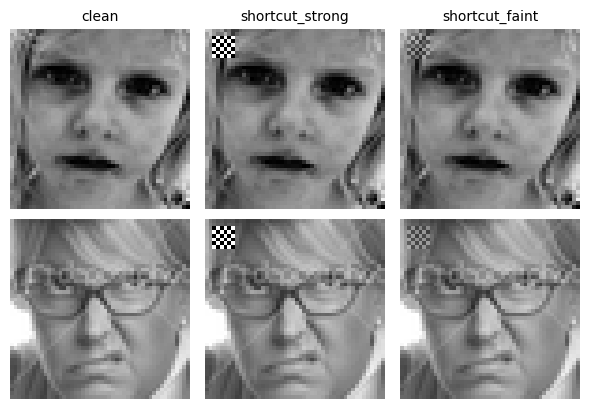

In [ ]:
ex = X_test[[np.where(y_test == TARGET)[0][0], np.where(y_test != TARGET)[0][0]]]
fig, axes = plt.subplots(2, 3, figsize=(6, 4.2))
for r in range(2):
    for c, (name, alpha) in enumerate(CONDITIONS.items()):
        axes[r, c].imshow(add_marker(ex[r:r + 1], alpha)[0, :, :, 0], cmap="gray", vmin=0, vmax=1)
        axes[r, c].axis("off")
        if r == 0:
            axes[r, c].set_title(name, fontsize=10)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "marker_examples.pdf"), bbox_inches="tight")
plt.show()

## Model and training (same as the main notebook)

In [ ]:
def conv_block(x, filters, name, pool=True, drop=0.25):
    for i in (1, 2):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False, name=f"{name}_conv{i}")(x)
        x = layers.BatchNormalization(name=f"{name}_bn{i}")(x)
        x = layers.Activation("relu", name=f"{name}_relu{i}")(x)
    if pool:
        x = layers.MaxPooling2D(name=f"{name}_pool")(x)
    return layers.Dropout(drop, name=f"{name}_drop")(x)


def build_model():
    inp = keras.Input((IMG_SIZE, IMG_SIZE, 1), name="image")
    x = layers.RandomFlip("horizontal")(inp)
    x = layers.RandomRotation(0.05)(x)
    x = layers.RandomTranslation(0.1, 0.1)(x)
    x = layers.RandomZoom(0.1)(x)
    x = conv_block(x, 64, "block1")
    x = conv_block(x, 128, "block2")
    x = conv_block(x, 256, "block3")
    x = conv_block(x, 512, "block4", pool=False)
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dense(256, activation="relu", name="fc")(x)
    x = layers.Dropout(0.5)(x)
    out = layers.Dense(NUM_CLASSES, name="logits")(x)
    return keras.Model(inp, out, name="fer_cnn")

In [ ]:
EPOCHS = 60
BATCH_SIZE = 64
LR = 1e-3
RETRAIN = False  # set True to ignore saved models

freq = np.bincount(y_train, minlength=NUM_CLASSES) / len(y_train)
class_weight = {c: float(w) for c, w in enumerate(np.sqrt(1 / (NUM_CLASSES * freq)))}

def make_ds(X, y, shuffle):
    ds = tf.data.Dataset.from_tensor_slices((X, keras.utils.to_categorical(y, NUM_CLASSES)))
    if shuffle:
        ds = ds.shuffle(len(X), seed=SEED)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

def train(name, alpha):
    path = os.path.join(OUT_DIR, f"{name}.keras")
    if os.path.exists(path) and not RETRAIN:
        print(f"{name}: loading saved model")
        return keras.models.load_model(path)

    keras.utils.set_random_seed(SEED)
    Xtr = plant(X_train, y_train, alpha, seed=1)
    Xva = plant(X_val, y_val, alpha, seed=2)
    train_ds, val_ds = make_ds(Xtr, y_train, True), make_ds(Xva, y_val, False)

    model = build_model()
    schedule = keras.optimizers.schedules.CosineDecay(LR, decay_steps=EPOCHS * len(train_ds), alpha=0.01)
    model.compile(optimizer=keras.optimizers.AdamW(schedule, weight_decay=1e-4),
                  loss=keras.losses.CategoricalCrossentropy(from_logits=True, label_smoothing=0.1),
                  metrics=["accuracy"])
    model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, class_weight=class_weight, verbose=2,
              callbacks=[keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=15,
                                                       restore_best_weights=True)])
    model.save(path)
    return model

models = {name: train(name, alpha) for name, alpha in CONDITIONS.items()}

clean: loading saved model
shortcut_strong: loading saved model
shortcut_faint: loading saved model


## 1. Does the model actually use the shortcut?

- **Clean accuracy:** accuracy on the untouched test set.
- **Flip rate:** take test faces that are *not* the target emotion and that the model doesn't already call the target, add the marker, and count how often the prediction switches to the target. The marker is the only thing that changed, so a flip means the model is using it.

Every model is scored with the strong marker and with its own training marker. The clean model is the control: it never saw a marker, so its flip rate should stay near zero.

In [ ]:
def predict(model, X):
    return model.predict(X, batch_size=256, verbose=0)

clean_logits = {n: predict(m, X_test) for n, m in models.items()}

rows, flipped = [], {}
for name, model in models.items():
    pred_clean = clean_logits[name].argmax(1)
    pool = np.where((y_test != TARGET) & (pred_clean != TARGET))[0]
    test_alpha = CONDITIONS[name] or 1.0
    pred_marked = predict(model, add_marker(X_test[pool], test_alpha)).argmax(1)
    pred_strong = predict(model, add_marker(X_test[pool], 1.0)).argmax(1)
    flipped[name] = pool[pred_marked == TARGET]
    rows.append({
        "model": name,
        "clean acc": (pred_clean == y_test).mean(),
        f"clean recall ({EMOTIONS[TARGET]})": (pred_clean[y_test == TARGET] == TARGET).mean(),
        "test marker alpha": test_alpha,
        "flip rate": (pred_marked == TARGET).mean(),
        "flip rate (strong marker)": (pred_strong == TARGET).mean(),
        "n flipped": len(flipped[name]),
    })

behavior = pd.DataFrame(rows).set_index("model")
behavior.round(3)

,clean acc,clean recall (Sad),test marker alpha,flip rate,flip rate (strong marker),n flipped
model,,,,,,
clean,0.675,0.549,1.0,0.009,0.009,23
shortcut_strong,0.617,0.114,1.0,0.825,0.825,2416
shortcut_faint,0.671,0.500,0.3,0.218,0.133,592


## 2. Does Grad-CAM point at the marker?

Grad-CAM is the same from-scratch implementation as the main notebook. For every image where the marker flipped the prediction we know the marker caused that prediction, so we measure:

- **Energy on marker:** fraction of the heatmap's total mass inside the marker box. Chance (a flat map) equals the box's share of the image.
- **Pointing game:** whether the heatmap's peak falls inside the box, allowing one feature-map cell of slack (4 px at `block3`, 8 px at `block4`), since a 6x6 map can't place its peak more precisely than that. The strict version is reported too.

We score two layers: `block3` (12x12 maps) and `block4` (6x6, the default).

In [ ]:
class GradCAM:
    def __init__(self, model, layer_name="block4_relu2", relu=True):
        self.relu = relu
        self.grad_model = keras.Model(model.inputs, [model.get_layer(layer_name).output, model.output])

    def __call__(self, images, class_idx):
        images = tf.convert_to_tensor(images, tf.float32)
        with tf.GradientTape() as tape:
            acts, logits = self.grad_model(images, training=False)
            score = tf.gather(logits, tf.cast(class_idx, tf.int32), axis=1, batch_dims=1)
        grads = tape.gradient(score, acts)
        weights = tf.reduce_mean(grads, axis=(1, 2), keepdims=True)
        cam = tf.reduce_sum(weights * acts, axis=-1)
        if self.relu:
            cam = tf.nn.relu(cam)
        cam = tf.image.resize(cam[..., None], images.shape[1:3], method="bilinear")[..., 0].numpy()
        peak = np.abs(cam).reshape(len(cam), -1).max(1)[:, None, None]
        return cam / np.maximum(peak, 1e-8)

    def batched(self, images, class_idx, bs=128):
        return np.concatenate([self(images[s:s + bs], class_idx[s:s + bs]) for s in range(0, len(images), bs)])


LAYERS = {"block3": "block3_relu2", "block4": "block4_relu2"}
CELL = {"block3": 4, "block4": 8}  # pixels per feature-map cell (12x12 and 6x6 maps)

def grow(mask, r):
    out = np.zeros_like(mask)
    rr, cc = np.where(mask)
    out[max(rr.min() - r, 0):rr.max() + r + 1, max(cc.min() - r, 0):cc.max() + r + 1] = True
    return out

def marker_scores(cams, lname):
    # a peak counts as a hit if it lands within one feature-map cell of the scored box,
    # since the map can't be more precise than its own grid
    total = cams.reshape(len(cams), -1).sum(1)
    energy = cams[:, box].sum(1) / np.maximum(total, 1e-8)
    peak = cams.reshape(len(cams), -1).argmax(1)
    tol_box = grow(box, CELL[lname])
    return energy, tol_box.ravel()[peak], box.ravel()[peak], tol_box.mean()

In [ ]:
rows, energies, example_cams = [], {}, {}
for name, model in models.items():
    if CONDITIONS[name] == 0:
        continue
    idx = flipped[name]
    if len(idx) == 0:
        print(f"{name}: marker never flipped a prediction, nothing to score")
        continue
    Xm = add_marker(X_test[idx], CONDITIONS[name])
    target = np.full(len(idx), TARGET)
    for lname, layer in LAYERS.items():
        cams = GradCAM(model, layer).batched(Xm, target)
        energy, hit, strict, hit_chance = marker_scores(cams, lname)
        energies[(name, lname)] = energy
        example_cams[(name, lname)] = cams[:8]
        rows.append({"model": name, "layer": lname, "n": len(idx),
                     "energy on marker": energy.mean(), "energy (median)": np.median(energy),
                     "energy chance": CHANCE, "pointing hit rate": hit.mean(),
                     "pointing chance": hit_chance, "pointing (strict box)": strict.mean()})

# control: the clean model on the same marked images, explaining its own prediction
for name in sorted({k[0] for k in energies}):
    idx = flipped[name]
    Xm = add_marker(X_test[idx], CONDITIONS[name])
    pred = predict(models["clean"], Xm).argmax(1)
    for lname, layer in LAYERS.items():
        energy, hit, strict, hit_chance = marker_scores(GradCAM(models["clean"], layer).batched(Xm, pred), lname)
        energies[(f"clean on {name} images", lname)] = energy
        rows.append({"model": f"clean (control, {name} images)", "layer": lname, "n": len(idx),
                     "energy on marker": energy.mean(), "energy (median)": np.median(energy),
                     "energy chance": CHANCE, "pointing hit rate": hit.mean(),
                     "pointing chance": hit_chance, "pointing (strict box)": strict.mean()})

gradcam_scores = pd.DataFrame(rows)
gradcam_scores.round(3)

,model,layer,n,energy on marker,energy (median),energy chance,pointing hit rate,pointing chance,pointing (strict box)
0,shortcut_strong,block3,2416,0.178,0.188,0.043,0.824,0.085,0.279
1,shortcut_strong,block4,2416,0.245,0.247,0.043,0.993,0.141,0.884
2,shortcut_faint,block3,592,0.133,0.126,0.043,0.861,0.085,0.578
3,shortcut_faint,block4,592,0.193,0.193,0.043,0.922,0.141,0.012
4,"clean (control, shortcut_faint images)",block3,592,0.056,0.051,0.043,0.193,0.085,0.140
5,"clean (control, shortcut_faint images)",block4,592,0.022,0.022,0.043,0.012,0.141,0.000
6,"clean (control, shortcut_strong images)",block3,2416,0.059,0.051,0.043,0.132,0.085,0.115
7,"clean (control, shortcut_strong images)",block4,2416,0.023,0.022,0.043,0.005,0.141,0.000


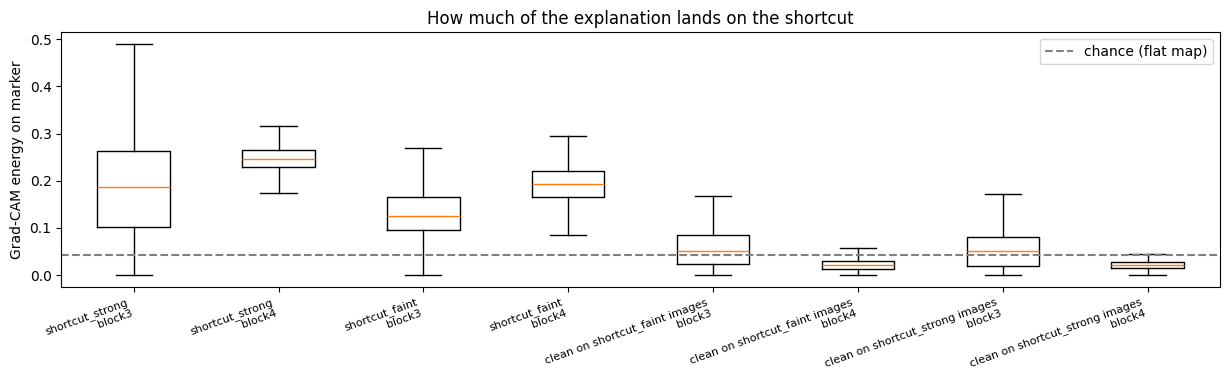

In [ ]:
keys = list(energies)
fig, ax = plt.subplots(figsize=(1.3 * len(keys) + 2, 4))
ax.boxplot([energies[k] for k in keys], showfliers=False)
ax.set_xticks(range(1, len(keys) + 1), [f"{a}\n{b}" for a, b in keys], fontsize=8, rotation=20, ha="right")
ax.axhline(CHANCE, ls="--", c="gray", label="chance (flat map)")
ax.set_ylabel("Grad-CAM energy on marker")
ax.set_title("How much of the explanation lands on the shortcut")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "marker_energy.pdf"), bbox_inches="tight")
plt.show()

Side by side: the same marked faces explained by the clean model and by each shortcut model. Every image in this grid was classified as the target emotion *because of* the marker.

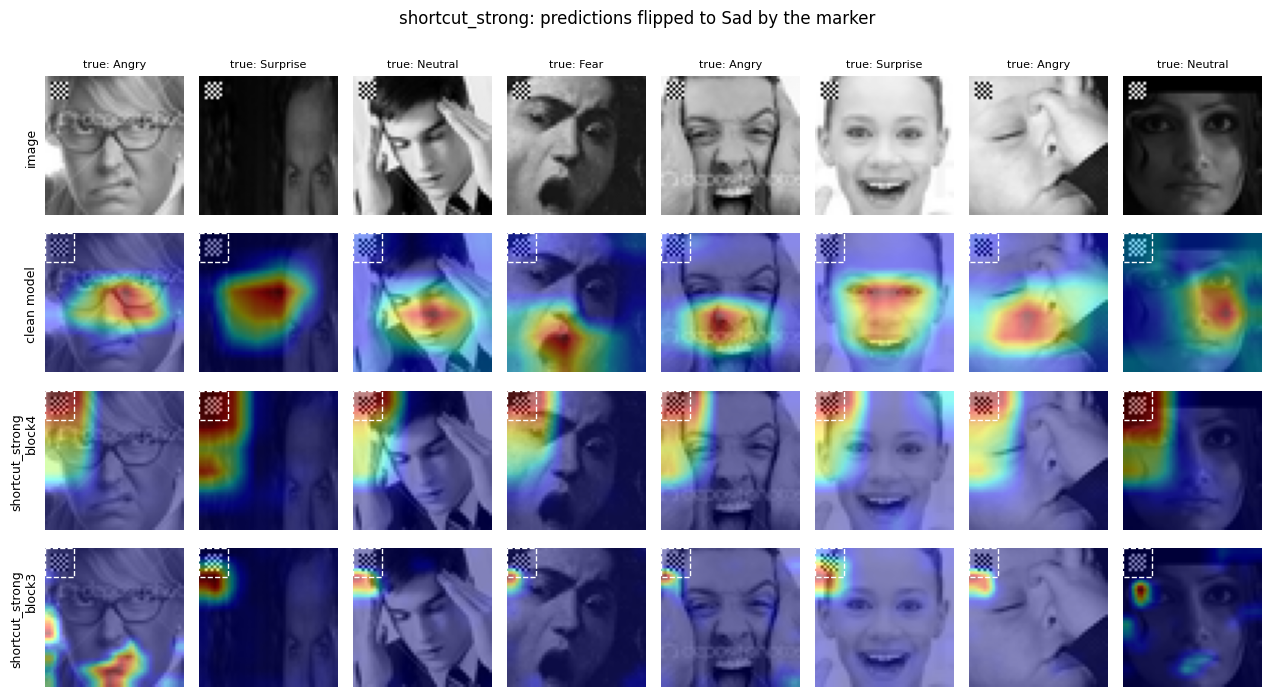

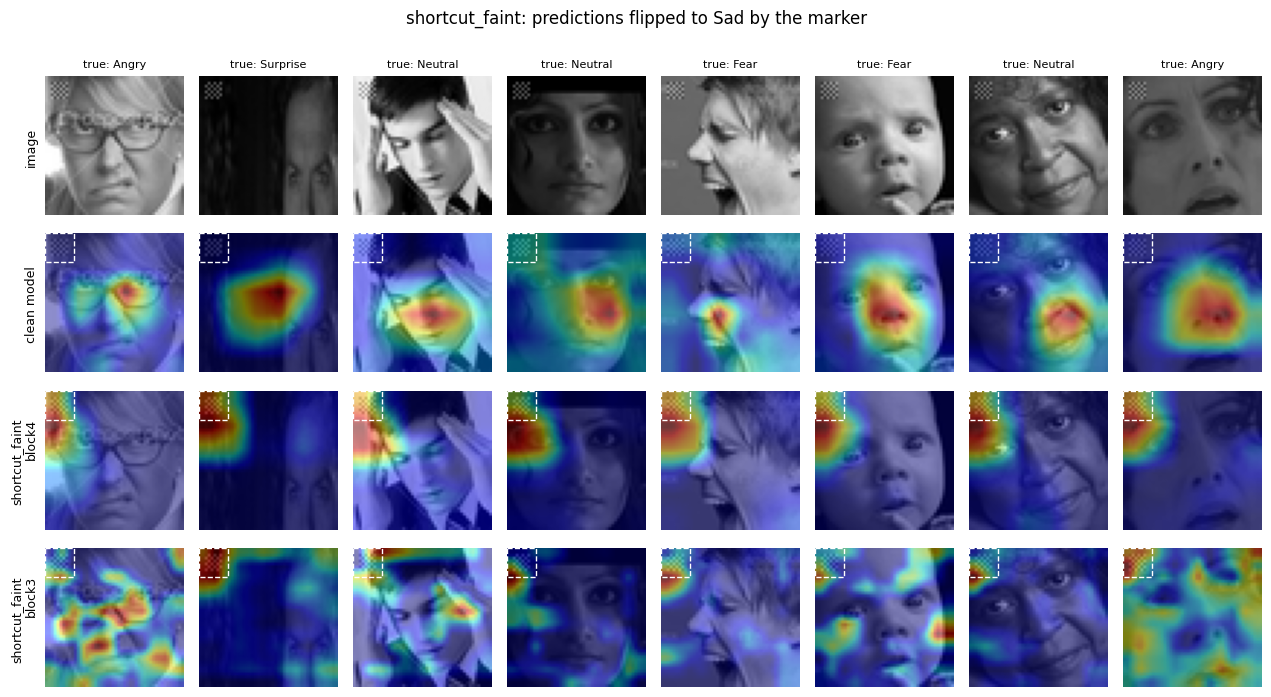

In [ ]:
def overlay(ax, img, cam):
    ax.imshow(img, cmap="gray", vmin=0, vmax=1)
    ax.imshow(cam, cmap="jet", alpha=0.45, vmin=0, vmax=1)
    ax.add_patch(plt.Rectangle((C0 - PAD - 0.5, R0 - PAD - 0.5), SIZE + 2 * PAD, SIZE + 2 * PAD,
                               fill=False, ec="white", lw=1, ls="--"))
    ax.axis("off")

for name in [n for n in CONDITIONS if (n, "block4") in example_cams]:
    idx = flipped[name][:8]
    Xm = add_marker(X_test[idx], CONDITIONS[name])
    clean_cams = GradCAM(models["clean"]).batched(Xm, predict(models["clean"], Xm).argmax(1))
    rows_ = [("image", None), ("clean model", clean_cams),
             (f"{name}\nblock4", example_cams[(name, "block4")]),
             (f"{name}\nblock3", example_cams[(name, "block3")])]
    fig, axes = plt.subplots(len(rows_), len(idx), figsize=(1.6 * len(idx), 1.75 * len(rows_)), squeeze=False)
    for r, (label, cams) in enumerate(rows_):
        for j in range(len(idx)):
            if cams is None:
                axes[r, j].imshow(Xm[j, :, :, 0], cmap="gray", vmin=0, vmax=1); axes[r, j].axis("off")
                axes[r, j].set_title(f"true: {EMOTIONS[y_test[idx[j]]]}", fontsize=8)
            else:
                overlay(axes[r, j], Xm[j, :, :, 0], cams[j])
        axes[r, 0].text(-3, 24, label, rotation=90, va="center", ha="right", fontsize=9)
    plt.suptitle(f"{name}: predictions flipped to {EMOTIONS[TARGET]} by the marker", y=1.0)
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, f"examples_{name}.pdf"), bbox_inches="tight")
    plt.show()

## 3. Sanity check: weight randomization

Following Adebayo et al. (2018), we randomize the weights from the top of the network down, one block at a time, and compare each new heatmap to the original with Spearman rank correlation. If Grad-CAM depends on what the model learned, the correlation should drop toward zero. If it stays high, the heatmap is mostly reflecting the input image rather than the model. Run on the clean model. We compare maps before the final ReLU, since a randomized network often gives an all-zero map after it and the correlation is then undefined.

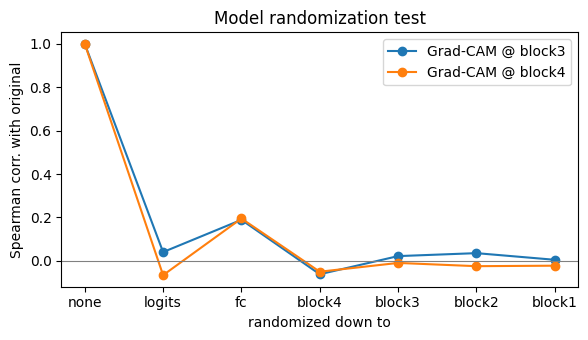

,block3,block4
none,1.000,1.000
logits,0.040,-0.066
fc,0.189,0.195
block4,-0.062,-0.050
block3,0.022,-0.010
block2,0.035,-0.025
block1,0.005,-0.022


In [ ]:
N_SANITY = 300
rng = np.random.default_rng(SEED)
s_idx = rng.choice(len(X_test), N_SANITY, replace=False)
s_cls = clean_logits["clean"][s_idx].argmax(1)

base = models["clean"]
orig = {l: GradCAM(base, layer, relu=False).batched(X_test[s_idx], s_cls) for l, layer in LAYERS.items()}

stages = ["logits", "fc", "block4", "block3", "block2", "block1"]
rand_model = keras.models.clone_model(base)
rand_model.set_weights(base.get_weights())
w_rng = np.random.default_rng(0)

sanity = {l: [1.0] for l in LAYERS}
for stage in stages:
    for layer in rand_model.layers:
        if layer.name.startswith(stage) and isinstance(layer, (layers.Conv2D, layers.Dense)):
            layer.set_weights([w_rng.normal(0, w.std() + 1e-8, w.shape).astype("float32")
                               for w in layer.get_weights()])
    for l, layer in LAYERS.items():
        cams = GradCAM(rand_model, layer, relu=False).batched(X_test[s_idx], s_cls)
        rho = [spearmanr(a.ravel(), b.ravel())[0] for a, b in zip(orig[l], cams)]
        sanity[l].append(float(np.nanmean(rho)))

fig, ax = plt.subplots(figsize=(6, 3.5))
for l in LAYERS:
    ax.plot(["none"] + stages, sanity[l], "o-", label=f"Grad-CAM @ {l}")
ax.axhline(0, c="gray", lw=0.8)
ax.set_xlabel("randomized down to")
ax.set_ylabel("Spearman corr. with original")
ax.set_title("Model randomization test")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "sanity_randomization.pdf"), bbox_inches="tight")
plt.show()
pd.DataFrame(sanity, index=["none"] + stages).round(3)

## 4. Deletion test

Gray out the top-k% of pixels ranked by Grad-CAM and track the model's probability for its original prediction. A faithful map should make confidence fall faster than deleting random pixels. Lower area under the curve (AUC) means more faithful.

Deleted pixels are replaced with the image mean. Because a solid gray blob is itself unusual input, the clean model is also run with a blurred-image fill, to check the result doesn't depend on that choice.

Run for the clean model on clean images, and for each shortcut model on its flipped marked images, where a faithful map should delete the marker first and undo the flip.

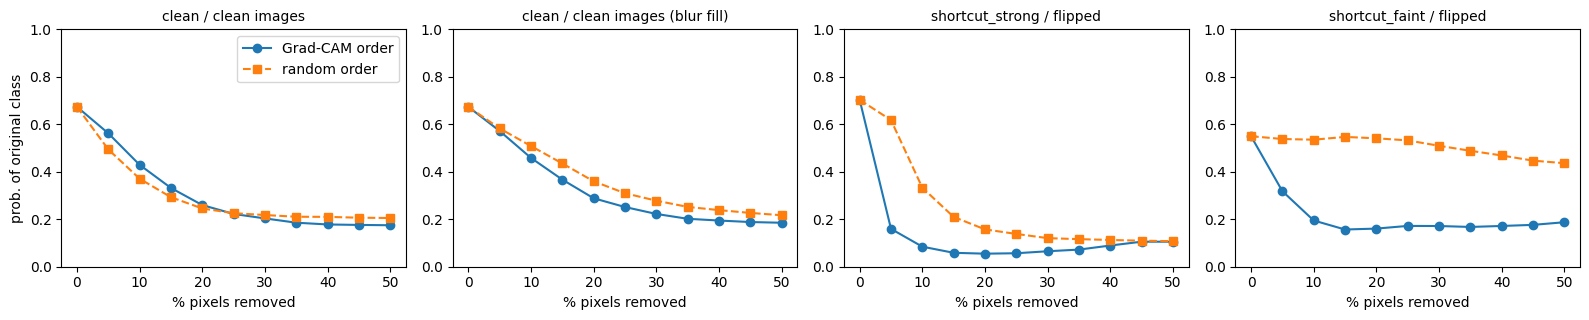

,AUC gradcam,AUC random
run,,
clean / clean images,0.297,0.291
clean / clean images (blur fill),0.317,0.364
shortcut_strong / flipped,0.115,0.232
shortcut_faint / flipped,0.206,0.510


In [ ]:
FRACS = np.linspace(0, 0.5, 11)
trapz = getattr(np, "trapezoid", None) or np.trapz

from scipy.ndimage import gaussian_filter

def deletion_curve(model, X, cls, cams, fill="mean", seed=0):
    rng = np.random.default_rng(seed)
    n, P = len(X), IMG_SIZE * IMG_SIZE
    flatX = X.reshape(n, P)
    if fill == "mean":
        fillX = np.repeat(flatX.mean(1, keepdims=True), P, axis=1)
    else:
        fillX = gaussian_filter(X[..., 0], sigma=(0, 4, 4)).reshape(n, P)
    curves = {}
    for kind in ("gradcam", "random"):
        if kind == "gradcam":
            order = np.argsort(-(cams.reshape(n, P) + 1e-6 * rng.random((n, P))), axis=1)
        else:
            order = np.argsort(rng.random((n, P)), axis=1)
        probs = []
        for f in FRACS:
            k = int(f * P)
            Xd = flatX.copy()
            rows_ = np.repeat(np.arange(n), k)
            cols_ = order[:, :k].ravel()
            Xd[rows_, cols_] = fillX[rows_, cols_]
            p = tf.nn.softmax(predict(model, Xd.reshape(X.shape))).numpy()
            probs.append(p[np.arange(n), cls].mean())
        curves[kind] = np.array(probs)
    return curves

del_runs = {}
cls = clean_logits["clean"][s_idx].argmax(1)
clean_cams = GradCAM(models["clean"]).batched(X_test[s_idx], cls)
del_runs["clean / clean images"] = deletion_curve(models["clean"], X_test[s_idx], cls, clean_cams)
del_runs["clean / clean images (blur fill)"] = deletion_curve(models["clean"], X_test[s_idx], cls, clean_cams, fill="blur")
for name in CONDITIONS:
    if (name, "block4") not in energies:
        continue
    idx = flipped[name][:N_SANITY]
    Xm = add_marker(X_test[idx], CONDITIONS[name])
    t = np.full(len(idx), TARGET)
    del_runs[f"{name} / flipped"] = deletion_curve(models[name], Xm, t, GradCAM(models[name]).batched(Xm, t))

fig, axes = plt.subplots(1, len(del_runs), figsize=(4 * len(del_runs), 3.3), squeeze=False)
rows = []
for ax, (label, c) in zip(axes[0], del_runs.items()):
    ax.plot(FRACS * 100, c["gradcam"], "o-", label="Grad-CAM order")
    ax.plot(FRACS * 100, c["random"], "s--", label="random order")
    ax.set_title(label, fontsize=10); ax.set_xlabel("% pixels removed"); ax.set_ylim(0, 1)
    rows.append({"run": label, **{f"AUC {k}": trapz(v, FRACS) / FRACS[-1] for k, v in c.items()}})
axes[0, 0].set_ylabel("prob. of original class"); axes[0, 0].legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "deletion.pdf"), bbox_inches="tight")
plt.show()

deletion = pd.DataFrame(rows).set_index("run")
deletion.round(3)

## Summary

Everything the paper needs in one place. Copy this output back.

In [ ]:
summary = {
    "target": EMOTIONS[TARGET], "mark_frac": MARK_FRAC, "chance_energy": float(CHANCE),
    "behavior": behavior.round(4).reset_index().to_dict("records"),
    "gradcam_on_marker": gradcam_scores.round(4).to_dict("records"),
    "sanity_spearman": {l: dict(zip(["none"] + stages, map(lambda v: round(v, 4), s))) for l, s in sanity.items()},
    "deletion_auc": deletion.round(4).reset_index().to_dict("records"),
}
with open(os.path.join(OUT_DIR, "results.json"), "w") as f:
    json.dump(summary, f, indent=1, default=float)
print(json.dumps(summary, indent=1, default=float))

{
 "target": "Sad",
 "mark_frac": 0.8,
 "chance_energy": 0.043402777777777776,
 "behavior": [
  {
   "model": "clean",
   "clean acc": 0.6751,
   "clean recall (Sad)": 0.5488,
   "test marker alpha": 1.0,
   "flip rate": 0.0086,
   "flip rate (strong marker)": 0.0086,
   "n flipped": 23
  },
  {
   "model": "shortcut_strong",
   "clean acc": 0.6166,
   "clean recall (Sad)": 0.1145,
   "test marker alpha": 1.0,
   "flip rate": 0.8254,
   "flip rate (strong marker)": 0.8254,
   "n flipped": 2416
  },
  {
   "model": "shortcut_faint",
   "clean acc": 0.6709,
   "clean recall (Sad)": 0.5,
   "test marker alpha": 0.3,
   "flip rate": 0.2176,
   "flip rate (strong marker)": 0.1327,
   "n flipped": 592
  }
 ],
 "gradcam_on_marker": [
  {
   "model": "shortcut_strong",
   "layer": "block3",
   "n": 2416,
   "energy on marker": 0.17829999327659607,
   "energy (median)": 0.1875,
   "energy chance": 0.0434,
   "pointing hit rate": 0.8237,
   "pointing chance": 0.0851,
   "pointing (strict box)": 

In [ ]:
if IN_COLAB:
    import shutil
    from google.colab import files
    shutil.make_archive("/content/shortcut_figs", "zip", FIG_DIR)
    files.download("/content/shortcut_figs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>